# Inquilinos que gastan más del 40 % de su renta en vivienda

In [ ]:
# Parámetros de la gráfica
SLUG = "vivienda"  # carpeta en research/temas/
GRAFICA_ID = "sobrecarga-coste-inquilinos"  # id de la gráfica (kebab-case) = nombre del notebook
TITULO = "Inquilinos que gastan más del 40 % de su renta en vivienda"  # `titulo` de la gráfica en config.json
DESDE = 1976  # inicio de la ventana temporal (METODOLOGIA §2.3)
TIPO = "serie_temporal"  # serie_temporal | por_ccaa | solo_espana
VISTA = "lineas"  # `vista` de la gráfica en config.json: lineas | ultimo_anio | proyeccion | categorias
EJE_MAX = None  # `eje_max` de la gráfica en config.json; None = el que piden los datos
UNIDAD = "% de la población en alquiler a precio de mercado"  # unidad del indicador
CSV_FORMATO = "es"  # CSV: "es" (separador ; y coma decimal, Excel en español) o "int" (, y punto)
CSV_DECIMALES = 2  # decimales del CSV (el JSON guarda el valor completo)
DIR_SALIDA = None  # solo tests; None = temas/<SLUG>/data/

## 1. Contexto

**Qué mide.** Qué parte de la población que vive de alquiler a precio de mercado está en hogares cuyos gastos de vivienda superan el 40 % de su renta disponible (la «tasa de sobrecarga» de Eurostat).

**Cómo se lee.** Un valor de 30 significa que tres de cada diez inquilinos a precio de mercado dedican a la vivienda más del 40 % de su renta.

**Limitaciones.**
- Eurostat cuenta todos los gastos de la vivienda (alquiler, suministros, comunidad) y descuenta las ayudas a la vivienda.
- EE. UU. y Canadá: la OCDE solo cuenta hipoteca y alquiler, y en España da valores distintos de los de Eurostat; al no ser comparables, esas series quedan sin dato (ver la comparación en la transformación). La OCDE no publica una media de sus países.

## 2. Descarga

- **España y UE-27:** Eurostat `ilc_lvho07c` (inquilinos a precio de mercado, `RENT_MKT`, %).
- **Comparación:** OECD Affordable Housing Database, HC1.2 (hoja `HC12_A3_a`, «Rent (private)», proporción × 100).

In [ ]:
import sys
from pathlib import Path

# Raíz del proyecto (la carpeta con global.json y lib/), buscando hacia arriba desde el directorio de ejecución
RAIZ = next((p for p in [Path.cwd(), *Path.cwd().parents] if (p / "global.json").exists()), None)
if RAIZ is None:
    raise FileNotFoundError(
        "No se encuentra global.json. Abre el notebook desde su carpeta (temas/<tema>/notebooks/) "
        "dentro del repositorio completo; consulta el README para instalar el entorno."
    )
sys.path.insert(0, str(RAIZ))

import pandas as pd

from lib import estilos
from lib.writer import construir_grafica_data, write_grafica_data

from datetime import date

from lib import eurostat, oecd, oecd_ahd
from lib.tipos import FuenteMeta


def descargar():
    euro, f_euro = eurostat.get("ilc_lvho07c", {"freq": "A", "unit": "PC", "tenure": "RENT_MKT"}, desde=DESDE)
    ahd, _ = oecd_ahd.get("HC1-2-Housing-costs-over-income", "HC12_A3_a", categoria="Rent (private)",
                          paises={"Spain": "espana", "United States": "eeuu", "Canada": "canada"}, escala=100, desde=DESDE)
    return euro, f_euro, ahd


euro, f_euro, ahd = descargar()

## 3. Transformación

Se compara en España la cifra de Eurostat con la de la OCDE. Si no coinciden, EE. UU. y Canadá se dejan sin dato en lugar de mezclar dos definiciones.

In [ ]:
def anadir_sin_dato(df, fuentes, sin_dato):
    """Añade las series de la cesta sin dato comparable (todo `null`) con la fuente consultada."""
    hoy = date.today().isoformat()
    vacias = pd.DataFrame({"serie": list(sin_dato), "periodo": DESDE, "valor": float("nan")})
    extra = [FuenteMeta(s, org, cod, url, hoy) for s, (org, cod, url) in sin_dato.items()]
    return pd.concat([df, vacias], ignore_index=True), [*fuentes, *extra]

# ¿Es comparable la OCDE con Eurostat? Se mira en España, que está en las dos fuentes
comun = euro[euro.serie == "espana"].merge(ahd[ahd.serie == "espana"], on="periodo", suffixes=("_eurostat", "_ocde"))
DIF = (comun["valor_ocde"] - comun["valor_eurostat"]).abs().mean()
print(comun.round(1).to_string(index=False))
print(f"Diferencia media en España (sobrecarga): {DIF:.1f} puntos")

df, fuentes = euro, f_euro
AHD = ("OECD", "Affordable Housing Database, HC1-2-Housing-costs-over-income (HC12_A3_a, consultada, no usada)", "https://webfs.oecd.org/els-com/Affordable_Housing_Database/HC1-2-Housing-costs-over-income.xlsx")
df, fuentes = anadir_sin_dato(df, fuentes, {"ocde": AHD, "eeuu": AHD, "canada": AHD})

NOTAS = [
    "España y UE-27: Eurostat ilc_lvho07c, tasa de sobrecarga del coste de la vivienda de la población en alquiler a precio de mercado: gastos totales de la vivienda, descontadas las ayudas, por encima del 40 % de la renta disponible del hogar. UE-27 de composición actual (EU27_2020).",
    f"EE. UU. y Canadá: la OECD Affordable Housing Database (HC1.2) solo cuenta hipoteca y alquiler; en España difiere de la cifra de Eurostat en {DIF:.1f} puntos de media en los años comunes, así que no es comparable y esas series quedan sin dato.",
    "OCDE: la OECD Affordable Housing Database no publica una media de sus países en las series anuales.",
]

serie_eurostat  periodo  valor_eurostat serie_ocde  valor_ocde
        espana     2010            43.4     espana        24.8
        espana     2011            42.7     espana        25.3
        espana     2012            44.7     espana        25.0
        espana     2013            42.3     espana        22.8
        espana     2014            47.5     espana        27.2
        espana     2015            43.3     espana        23.5
        espana     2016            43.0     espana        22.3
        espana     2017            42.1     espana        25.6
        espana     2018            38.1     espana        20.3
        espana     2019            37.4     espana        23.6
        espana     2020            35.9     espana        23.0
        espana     2021            40.9     espana        28.3
        espana     2022            39.4     espana        24.8
        espana     2023            30.6     espana        20.0
        espana     2024            28.1     espana     

## 4. Visualización

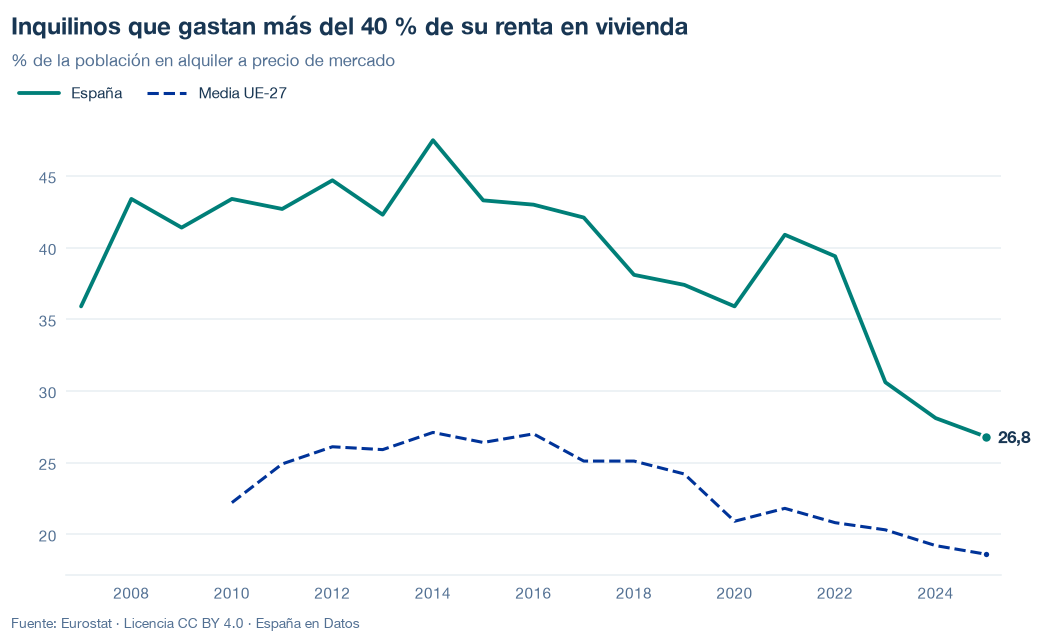

In [ ]:
datos = construir_grafica_data(
    df, fuentes, id=GRAFICA_ID, tipo=TIPO, unidad=UNIDAD, notas=NOTAS,
    generado_por=f"temas/{SLUG}/notebooks/{GRAFICA_ID}.ipynb", desde=DESDE,
)
fig = estilos.figura(datos, titulo=TITULO, vista=VISTA, eje_max=EJE_MAX)
estilos.mostrar(fig)

## 5. Exportación

Escribe `data/<id>.json` (validado contra el esquema) y `data/<id>.csv`, el mismo CSV que se descarga en la web.

In [ ]:
salida = Path(DIR_SALIDA) if DIR_SALIDA else RAIZ / "temas" / SLUG / "data"
ruta = write_grafica_data(
    df, fuentes, id=GRAFICA_ID, tipo=TIPO, unidad=UNIDAD, notas=NOTAS,
    generado_por=f"temas/{SLUG}/notebooks/{GRAFICA_ID}.ipynb", desde=DESDE,
    path=salida / f"{GRAFICA_ID}.json", csv_formato=CSV_FORMATO, csv_decimales=CSV_DECIMALES,
)
print(f"escrito: data/{ruta.name} y data/{ruta.stem}.csv")  # sin rutas locales en las salidas publicadas

escrito: data/sobrecarga-coste-inquilinos.json y data/sobrecarga-coste-inquilinos.csv


## 6. Fuentes, notas y licencia

- Eurostat, `ilc_lvho07c`.
- OECD Affordable Housing Database, HC1.2 (`HC12_A3_a`), solo para la comparación.

La fecha de consulta de cada serie está en `fuentes` del JSON; las notas, en `notas`, incluyen el primer año con dato de cada serie.

**Licencia:** datos, gráficos y textos CC BY 4.0; código MIT. Cita a España en Datos.